In [9]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import utils as ut

from sklearn.datasets import fetch_openml

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Introduction

This notebook gives an introduction to predicting the MNIST dataset using logistic regression. This is a baseline for the future trajectory of the project towards reservoir computing.

## Theory

### Weighted sum

For each image, logistic regression assigns a score $z_c$ to each digit $c\in\{0,1,...,9\}$. The score $z_c$ is computed via a weighted sum

$$z_c=\vec w_c\cdot\vec x + b_c$$

where:
- $\vec x$: The input image, a vector of $28^2=784$ elements representing each pixel. Each pixel originally has a brightness value between 0 and 255, but this is normalised to between 0 and 1.
- $\vec w_c$: A vector of $784$ elements of weights assigned to each pixel learnt by the model 
- $b_c$: A bias learnt by the model for each digit

### Softmax function

The softmax function

$$P(c|\vec x)=\frac{\exp(z_c)}{\sum^9_{j=0}\exp{z_j}}$$

converts the ten scores $z_c$ into ten probabilities that sum to 1. The digit with the highest probability becomes the prediction.

### Cost function
Error is calculated using a cross-entropy loss function $L$. For an image whose true class is $y$, the loss is
$$L=-\ln P(y|\vec x)$$

# Implementation
## Setup

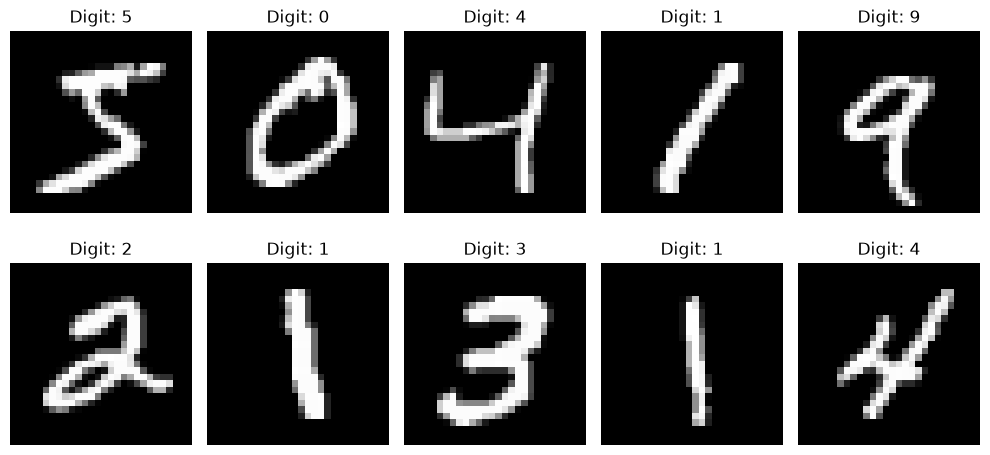

In [10]:
# retrieve MNIST dataset via OpenML
images, labels = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
labels = labels.astype(int)

# plot the first 10 images and label
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Digit: {labels[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
# normalise to values between 0 and 1
images = images.astype(np.float64) / 255.0

# name images as X and labels as y for conciseness
# first 60,000 pairs are used for training.
X_train = images[:60000]
y_train = labels[:60000]

# remaining 10,000 are used for testing
X_test = images[60000:]
y_test = labels[60000:]

print(X_train.shape, X_test.shape)

(60000, 784) (10000, 784)


Previously, we described $w_c$ and $b_c$ as a vector of length 784 and a number. This was in the context of one particular digit $c$. From here, we instead define `W` and `b` as a $784\times10$ matrix and a vector of size $10$ respectively. This allows us to represent the weights and biases of all $c\in\{0,1,...,9\}$ digits in single objects.

We can further expand by defining `Z` and `X` as $60000\times10$ and $60000\times728$ matrices as well. Thus, for all $N=60000$ images, we can represent their associated scores and pixel intensities all in one big matrix respectively.

In [12]:
num_elements = 28**2
num_classes  = 10

W = np.zeros((num_elements, num_classes))
b = np.zeros(num_classes)

In [13]:
# sanity check. all weights and biases are zero, so all digits should be equally probable

# here X_train has size 60000 * 784, so Z has size 60000 * 10
Z = X_train @ W + b
P = ut.softmax(Z)
print(P[1])

# expected result is C = -ln P = -ln(0.1) = 2.302585
loss = ut.cross_entropy(P, y_train)
print(loss)

[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
2.302585092994046


## Cost function and gradient descent
From the cross-entropy formula and the softmax function, we can obtain the gradient descent for weights and biases

$$\boxed{\frac{\partial C}{\partial w_{kc}}=\frac 1 N \sum^N_{i=1}(P_{ic}-Y_{ic})x_{ik}}$$

$$\boxed{\frac{\partial C}{\partial b_c}=\frac 1 N \sum^N_{i=1}(P_{ic}-Y_{ic})}$$

where $N=60000$ is the number of training samples.

A derivation of these results is provided in the PDF `log_regression_derivation.ipynb`.

In [14]:
N = 60000

# Convert labels into one-hot vectors
Y = np.zeros((N, 10))
Y[np.arange(N), y_train] = 1

# Difference between predicted probabilities and true labels
error = P - Y

# Gradients of the cost function
dW = X_train.T @ error / N
db = np.mean(error, axis=0)

print(dW.shape)  # (784, 10)
print(db.shape)  # (10,)

(784, 10)
(10,)


## Execution
Here, the model training is executed. I used this code here to test appropriate values for learning rate and number of epochs.

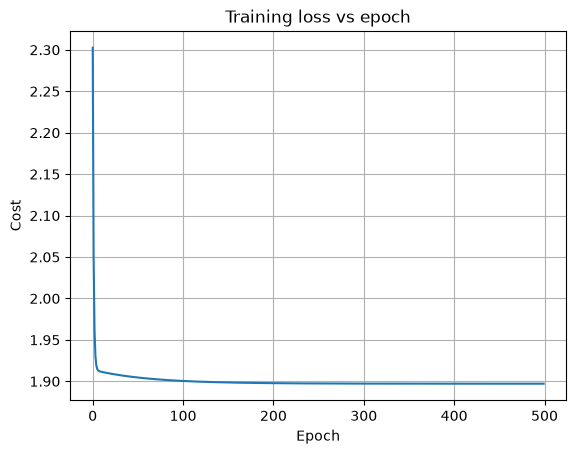

In [ ]:
# through experimentation with learning rate and epochs, i have found that
# the optimal settings are learning_rate = 0.3 and epochs = 1000
# i also experiment with appropriate choice of regularisation hyperparameter lambda,
# which is explained in the next notebook, regularisation.ipynb

learning_rate = 0.3
epochs = 500
lam = 1

losses = []
for epoch in range(epochs):
    Z = X_train @ W + b
    P = ut.softmax(Z)

    loss = ut.cross_entropy(P, y_train) + (lam / 2) * np.sum(W**2)
    losses.append(loss)

    error = P - Y
    dW = X_train.T @ error / N + lam * W
    db = np.mean(error, axis=0)

    W -= learning_rate * dW 
    b -= learning_rate * db

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Cost")
plt.title("Training loss vs epoch")
plt.grid(True)
plt.show()

In [16]:
Z_test = X_test @ W + b # Z_test is now a 10000 * 10 matrix

# predictions keeps the highest score in each row (axis 1), so its a vector of length 10000
predictions = np.argmax(Z_test, axis=1)

accuracy = np.mean(predictions == y_test) # if prediction == correct label, 1. else, 0. average over all.
print("Test accuracy:", accuracy)

Test accuracy: 0.7838
